# Series de tiempo en Python: ventas de vivienda nueva en Colombia

Este notebook pasa a Python el análisis de series de tiempo que vimos en R (Clases 15 y 16 y el script `series_tiempo_current - copia.r`) y lo aplica al ejemplo de **unidades de vivienda nueva vendidas en Colombia** (enero 2010 – octubre 2025), el mismo de `time_series_vivienda/time-series-vivienda.ipynb`.

**Ruta**

1. Datos y partición train / test
2. Exploración: tendencia, estacionalidad, diferencias, ACF y PACF
3. Modelos univariados: ingenuos, suavización exponencial (ETS) y ARIMA
4. Atípicos
5. ARIMAX: ARIMA con predictores y dummies
6. Supuestos sobre los residuos
7. Evaluación en test
8. Validación escalonada en origen (`tsCV`)
9. Modelo final y pronóstico

**Equivalencias R → Python.** Todo se hace con `statsmodels` (viene con Anaconda). Las funciones de R que no existen tal cual en Python las programamos aquí mismo, en versiones cortas.

| R | Python |
|---|---|
| `ts(..., frequency = 12)`, `window()` | `pd.Series` con índice mensual, `serie[:'2022-07']` |
| `diff(x)`, `diff(x, lag = 12)` | `x.diff()`, `x.diff(12)` |
| `Acf()`, `Pacf()` | `plot_acf()`, `plot_pacf()` |
| `naive()`, `snaive()` | repetir el último valor / los últimos 12 meses |
| `ets(model = "ZZZ")` | `ETSModel` + `ets_auto()` |
| `auto.arima()`, `auto.arima(xreg = )` | `ARIMA` + `auto_arima()`, `auto_arima(exog = )` |
| `tso()` (tsoutliers) | `detectar_atipicos()` |
| `adf.test()`, `Box.test(type = "Ljung-Box")` | `adfuller()`, `acorr_ljungbox()` |
| `accuracy()` | `accuracy()` |
| `tsCV()` | `ts_cv()` |

In [1]:
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.signal import lfilter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.2f}'.format)

# Estilo de las gráficas: la serie real va en gris y cada modelo conserva siempre su color
GRIS = '#52514e'
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
COLOR_MODELO = {'ETS': COLORES[0], 'ARIMA': COLORES[1], 'ARIMAX': COLORES[2],
                'Ingenuo': COLORES[3], 'Ingenuo estacional': COLORES[4]}
plt.rcParams.update({
    'figure.figsize': (12, 4), 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': GRIS, 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.8, 'xtick.color': '#898781', 'ytick.color': '#898781',
    'lines.linewidth': 1.8, 'axes.prop_cycle': plt.cycler(color=COLORES), 'legend.frameon': False,
})

## 1. Datos

| Columna | Descripción |
|---|---|
| `ventas` | **Y**: unidades de vivienda nueva vendidas en el mes |
| `desempleo` | Tasa de desempleo (%) |
| `ipc` | Variación porcentual mensual del IPC |
| `tasa_no_vis` | Tasa de interés promedio para adquisición de vivienda no VIS (%) |
| `tasa_vis` | Tasa de interés promedio para adquisición de vivienda VIS (%) |
| `iccv` | Variación porcentual mensual del costo de la construcción (ICCV / ICOCED) |
| `icc` | Índice de Confianza del Consumidor |
| `crisis_mcy`, `pandemia`, `paro`, `reactivacion` | Dummies de eventos |

In [2]:
datos = pd.read_excel('time_series_vivienda/Time-series-datos.xlsx')
datos.columns = ['fecha', 'ventas', 'desempleo', 'ipc', 'tasa_no_vis', 'tasa_vis', 'iccv', 'icc',
                 'crisis_mcy', 'pandemia', 'paro', 'reactivacion']
datos = datos.set_index('fecha').asfreq('MS')   # índice mensual: equivale a frequency = 12 en R
datos.tail(3)

,ventas,desempleo,ipc,tasa_no_vis,tasa_vis,iccv,icc,crisis_mcy,pandemia,paro,reactivacion
fecha,,,,,,,,,,,
2025-09-01,15085,8.17,0.32,12.02,11.69,-0.31,1.60,1,0,0,1
2025-10-01,15484,8.20,0.18,12.22,11.85,-0.40,13.60,1,0,0,1
2025-11-01,11499,NaN,0.07,12.36,12.02,NaN,17.00,1,0,0,1


La última fila (noviembre 2025) no trae desempleo ni ICCV. Igual que en R (`end = c(2025, 10)`), trabajamos hasta octubre 2025.

In [3]:
datos = datos.loc[:'2025-10']
ventas = datos['ventas'].astype(float)
datos.head()

,ventas,desempleo,ipc,tasa_no_vis,tasa_vis,iccv,icc,crisis_mcy,pandemia,paro,reactivacion
fecha,,,,,,,,,,,
2010-01-01,8758,14.88,0.69,13.70,13.04,0.58,7.10,0,0,0,0
2010-02-01,9751,12.69,0.83,13.70,12.92,0.35,11.50,0,0,0,0
2010-03-01,10226,11.96,0.25,13.66,12.94,0.46,16.10,0,0,0,0
2010-04-01,8759,12.44,0.46,13.62,12.78,0.44,19.30,0,0,0,0
2010-05-01,8771,12.26,0.10,13.37,12.76,0.53,22.50,0,0,0,0


In [4]:
# ¿En qué meses vale 1 cada dummy?
for c in ['pandemia', 'paro', 'reactivacion', 'crisis_mcy']:
    activos = datos.index[datos[c] == 1]
    print(f'{c:13s} {activos.min():%Y-%m} a {activos.max():%Y-%m}  ({len(activos)} meses)')

pandemia      2020-03 a 2020-03  (1 meses)
paro          2021-05 a 2021-05  (1 meses)
reactivacion  2020-06 a 2025-10  (65 meses)
crisis_mcy    2023-03 a 2025-10  (32 meses)


### Partición train / test

En series de tiempo la partición **no puede ser aleatoria**, porque rompe la estructura del tiempo: train son los datos más antiguos y test los más recientes. Los datos de test deben cubrir por lo menos el horizonte de planeación y, si hay estacionalidad, un ciclo completo (12 meses).

Usamos la misma partición del notebook de R: train hasta julio 2022 y test desde agosto 2022.

In [5]:
train = ventas[:'2022-07']
test = ventas['2022-08':]
print(f'train: {train.index[0]:%Y-%m} a {train.index[-1]:%Y-%m}  ({len(train)} meses)')
print(f'test:  {test.index[0]:%Y-%m} a {test.index[-1]:%Y-%m}  ({len(test)} meses)')

train: 2010-01 a 2022-07  (151 meses)
test:  2022-08 a 2025-10  (39 meses)


## 2. Exploración

En la gráfica buscamos los elementos de la Clase 15: **nivel**, **tendencia**, **estacionalidad** y **ciclos o rupturas** (por ejemplo, la pandemia).

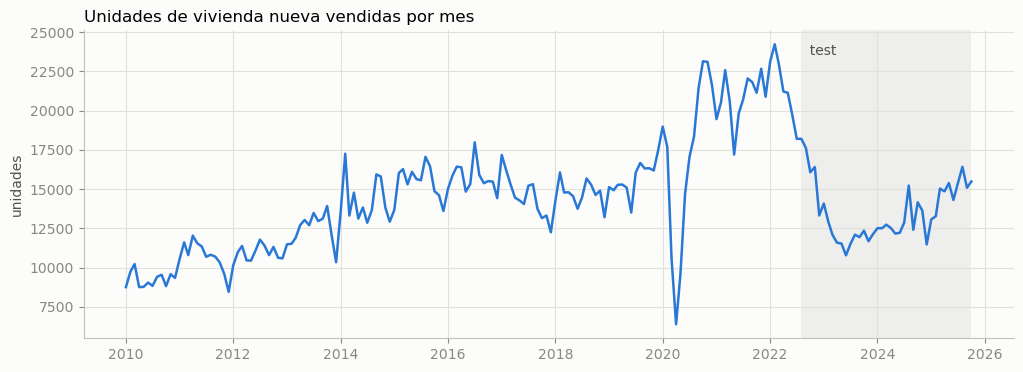

In [6]:
fig, ax = plt.subplots()
ax.plot(ventas, color=COLORES[0])
ax.axvspan(test.index[0], test.index[-1], color=GRIS, alpha=0.08, lw=0)
ax.text(test.index[0], ventas.max(), '  test', va='top', color=GRIS)
ax.set_title('Unidades de vivienda nueva vendidas por mes')
ax.set_ylabel('unidades')
plt.show()

- **Tendencia** creciente hasta 2022.
- **Atípicos** clarísimos en la pandemia: el desplome de marzo–mayo 2020 y el rebote posterior.
- **Ruptura** desde finales de 2022: las ventas caen con fuerza, al tiempo que suben las tasas de interés y empieza la crisis de *Mi Casa Ya* (dummy `crisis_mcy`, desde marzo 2023). Esa caída queda casi toda en **test**: el modelo no la ve cuando entrena. Esto va a pesar mucho en la evaluación.

### Descomposición: tendencia + estacionalidad + residuo

La descomposición STL separa la serie en sus componentes. Con ella medimos la **fuerza de la estacionalidad**: cerca de 0 significa que no hay estacionalidad y cerca de 1 que es muy marcada. `auto.arima` de R usa esta misma medida para decidir si hace una diferencia estacional (lo hace si supera 0.64).

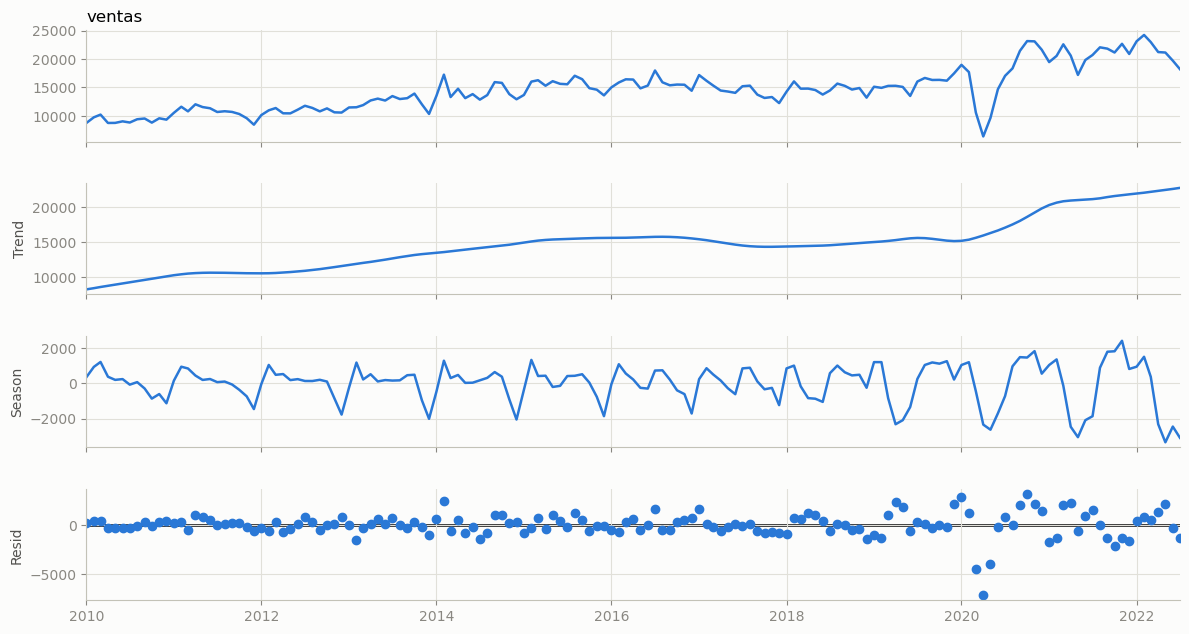

Fuerza de la estacionalidad en train: 0.47


In [7]:
def fuerza_estacional(y, m=12):
    stl = STL(y, period=m).fit()
    return max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())

fig = STL(train, period=12).fit().plot()
fig.set_size_inches(12, 7)
plt.show()
print(f'Fuerza de la estacionalidad en train: {fuerza_estacional(train):.2f}')

### Diferencias

Si veo tendencia y estacionalidad, diferencio para dejar la serie "plana" (Clase 16):

- **Diferencia regular** (febrero − enero, marzo − febrero, …) → quita la tendencia: `diff(x, differences = 1)` en R.
- **Diferencia estacional** (febrero de un año − febrero del año anterior) → quita la estacionalidad: `diff(x, lag = 12)` en R.

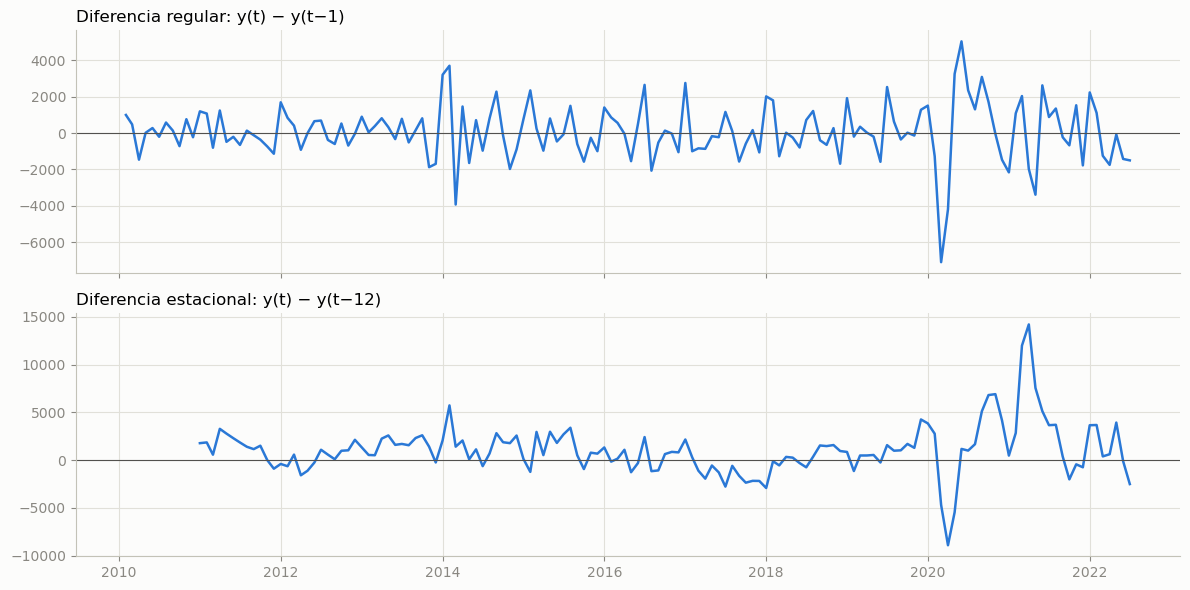

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(train.diff())
axes[0].set_title('Diferencia regular: y(t) − y(t−1)')
axes[1].plot(train.diff(12))
axes[1].set_title('Diferencia estacional: y(t) − y(t−12)')
for ax in axes:
    ax.axhline(0, color=GRIS, lw=0.8)
plt.tight_layout()
plt.show()

### Autocorrelación (ACF) y autocorrelación parcial (PACF)

Recordemos el ejemplo de la sal en la sopa de la Clase 15:

- **ACF**: relación **total** entre $y_t$ y $y_{t-k}$, incluido el efecto en cadena (antier → ayer → hoy). Se "apaga" lentamente.
- **PACF**: relación **directa** entre $y_t$ y $y_{t-k}$, quitando el efecto de los rezagos intermedios. Se "corta" donde ya no hay relación directa.

La franja azul es el intervalo de confianza: las barras que se salen de ella son autocorrelaciones significativas.

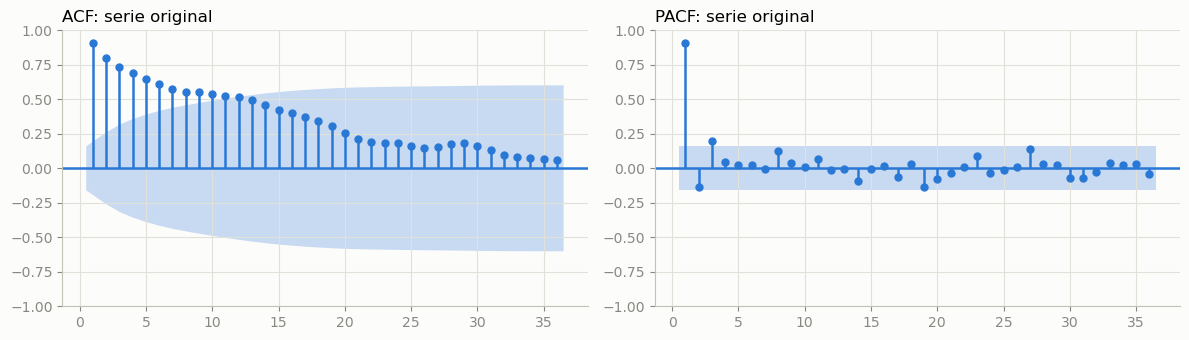

In [9]:
def graficar_acf_pacf(x, titulo, lags=36):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    plot_acf(x.dropna(), lags=lags, zero=False, ax=axes[0], title=f'ACF: {titulo}')
    plot_pacf(x.dropna(), lags=lags, zero=False, ax=axes[1], title=f'PACF: {titulo}', method='ywm')
    plt.tight_layout()
    plt.show()

graficar_acf_pacf(train, 'serie original')

La ACF de la serie original baja muy despacio: es la huella de la **tendencia** (la serie no es estacionaria). Por eso, como dice la clase, a las autocorrelaciones hay que quitarles primero la tendencia y la estacionalidad. Las miramos sobre la doble diferencia (estacional + regular):

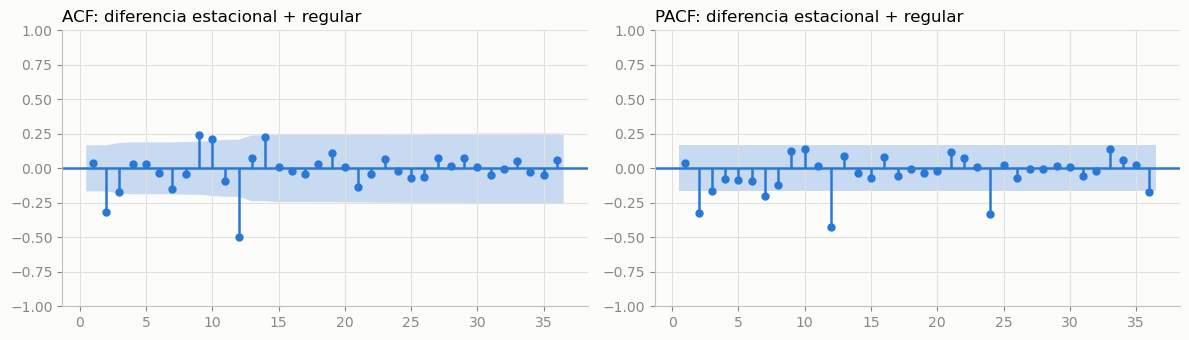

In [10]:
graficar_acf_pacf(train.diff(12).diff(), 'diferencia estacional + regular')

Después de la doble diferencia queda un pico negativo fuerte en el rezago 12 de la ACF (≈ −0.5), y la PACF decae en los rezagos 12 y 24. Ese patrón es típico de **sobre-diferenciar** la parte estacional: es probable que la diferencia estacional no haga falta. Lo confirma la fuerza estacional (≈ 0.47 < 0.64), y por eso el `auto_arima` de más abajo escoge D = 0.

### ¿De dónde salen la ACF y la PACF? (como en el script de R)

En R construimos los rezagos con `lag(producto1.train, -k)`; en pandas es `shift(k)`.

In [11]:
rezagos = pd.DataFrame({'y': train})
for k in range(1, 5):
    rezagos[f'y_lag{k}'] = train.shift(k)
rezagos = rezagos.dropna()   # dejo solo las filas completas
rezagos.head()

,y,y_lag1,y_lag2,y_lag3,y_lag4
fecha,,,,,
2010-05-01,"8,771.00","8,759.00","10,226.00","9,751.00","8,758.00"
2010-06-01,"9,044.00","8,771.00","8,759.00","10,226.00","9,751.00"
2010-07-01,"8,837.00","9,044.00","8,771.00","8,759.00","10,226.00"
2010-08-01,"9,413.00","8,837.00","9,044.00","8,771.00","8,759.00"
2010-09-01,"9,543.00","9,413.00","8,837.00","9,044.00","8,771.00"


In [12]:
# Matriz de correlaciones entre la serie y sus rezagos
rezagos.corr().round(3)

,y,y_lag1,y_lag2,y_lag3,y_lag4
y,1.00,0.92,0.81,0.76,0.73
y_lag1,0.92,1.00,0.92,0.81,0.76
y_lag2,0.81,0.92,1.00,0.92,0.81
y_lag3,0.76,0.81,0.92,1.00,0.92
y_lag4,0.73,0.76,0.81,0.92,1.00


In [13]:
# Se parece mucho a la ACF (no es idéntica porque la ACF usa la media y el tamaño de toda la serie)
print('Correlación de y con y_lag1..4:', rezagos.corr().iloc[0, 1:].values.round(3))
print('ACF rezagos 1..4:             ', acf(train, nlags=4)[1:].round(3))

Correlación de y con y_lag1..4: [0.915 0.813 0.759 0.734]
ACF rezagos 1..4:              [0.907 0.798 0.733 0.691]


La **autocorrelación parcial** de orden *k* es el coeficiente del rezago *k* en una regresión de $y_t$ sobre sus *k* primeros rezagos. Es decir, el efecto directo de $y_{t-k}$ una vez controlamos por los rezagos intermedios (lo mismo que hacíamos con `lm(producto1.train ~ ar1 + ar2, ...)`).

In [14]:
for k in range(1, 5):
    formula = 'y ~ ' + ' + '.join(f'y_lag{j}' for j in range(1, k + 1))
    coef = smf.ols(formula, data=rezagos).fit().params[f'y_lag{k}']
    print(f'k = {k}: coeficiente de y_lag{k} = {coef:6.3f}')
print('PACF rezagos 1..4:', pacf(train, nlags=4, method='ols')[1:].round(3))

k = 1: coeficiente de y_lag1 =  0.910
k = 2: coeficiente de y_lag2 = -0.151
k = 3: coeficiente de y_lag3 =  0.241
k = 4: coeficiente de y_lag4 =  0.088
PACF rezagos 1..4: [ 0.913 -0.146  0.248  0.088]


## 3. Modelos univariados

### Métricas de error

Programamos el equivalente de `accuracy()` de R, con el error definido como $e = \text{real} - \text{pronóstico}$:

- **ME** y **MPE**: sesgo. Si son negativos, el modelo **sobreestima**.
- **RMSE** y **MAE**: error típico, en unidades de vivienda.
- **MAPE**: error porcentual. Un MAPE de 35 es un error del 35 %. Entre más pequeño, mejor.
- **MASE**: error relativo al pronóstico ingenuo estacional dentro de train. Menor que 1 es mejor que el ingenuo y mayor que 1 es peor.

In [15]:
def accuracy(real, pronostico, train, m=12):
    e = real - pronostico
    escala = train.diff(m).abs().mean()   # MAE del ingenuo estacional en train (igual que en R)
    return pd.Series({
        'ME': e.mean(),
        'RMSE': np.sqrt((e ** 2).mean()),
        'MAE': e.abs().mean(),
        'MPE': (100 * e / real).mean(),
        'MAPE': (100 * e / real).abs().mean(),
        'MASE': e.abs().mean() / escala,
    })

def graficar_pronostico(ax, nombre, p, titulo=None, desde='2019-01'):
    ax.plot(ventas[desde:], color=GRIS, lw=1.4, label='real')
    ax.plot(p['pronostico'], color=COLOR_MODELO[nombre], lw=2, label='pronóstico')
    if 'inf95' in p:
        ax.fill_between(p.index, p['inf95'], p['sup95'], color=COLOR_MODELO[nombre], alpha=0.15, lw=0, label='intervalo 95 %')
    ax.axvline(test.index[0], color='#c3c2b7', lw=1)
    ax.set_title(titulo or nombre)

pronosticos = {}   # aquí guardamos el pronóstico de cada modelo sobre test

### 3.1 Pronósticos ingenuos

Son la línea base que cualquier modelo debería superar.

- **Ingenuo** (`naive()`): el pronóstico es el último valor observado. Es una caminata aleatoria, algo así como un KNN con K = 1.
- **Ingenuo estacional** (`snaive()`): el pronóstico de cada mes es el valor del mismo mes del año anterior.

In [16]:
pronosticos['Ingenuo'] = pd.DataFrame({'pronostico': train.iloc[-1]}, index=test.index)
pronosticos['Ingenuo estacional'] = pd.DataFrame({'pronostico': np.resize(train.iloc[-12:].values, len(test))}, index=test.index)

pd.DataFrame({nombre: accuracy(test, pronosticos[nombre]['pronostico'], train)
              for nombre in ['Ingenuo', 'Ingenuo estacional']}).T

,ME,RMSE,MAE,MPE,MAPE,MASE
Ingenuo,"-4,632.95","4,978.76","4,633.31",-36.44,36.44,2.42
Ingenuo estacional,"-8,031.36","8,340.99","8,031.36",-61.77,61.77,4.19


### 3.2 Suavización exponencial (ETS)

Es como un KNN ponderado: usa los datos pasados, pero le da más peso a los más recientes. Tiene tres componentes, **ETS(Error, Tendencia, Estacionalidad)**, y cada uno puede ser:

| Letra | Significado |
|---|---|
| N | No hay (*none*) |
| A | Aditivo |
| Ad | Aditivo amortiguado (*damped*), solo para la tendencia |
| M | Multiplicativo |

Los parámetros de suavización (α para el nivel, β para la tendencia, γ para la estacionalidad) van de 0 a 1: cerca de 1 significa que el componente se actualiza casi solo con el último dato, y cerca de 0 que casi no cambia en el tiempo.

`ets(model = "ZZZ")` en R prueba las combinaciones y se queda con la de menor AIC. `ets_auto()` hace lo mismo. Igual que R, descarta la combinación inestable *error aditivo + estacionalidad multiplicativa*.

> **Nota técnica.** En `statsmodels` la estimación de los estados iniciales a veces se queda en un mal óptimo local, así que usamos la inicialización heurística (`initialization_method='heuristic'`, de Hyndman et al.). Con ella el modelo elegido coincide con el de R.

In [17]:
def ets_auto(y, m=12):
    resultados, mejor, mejor_nombre = [], None, None
    for error, tendencia, estacional in itertools.product(['add', 'mul'], ['N', 'A', 'Ad'], ['N', 'add', 'mul']):
        if error == 'add' and estacional == 'mul':
            continue
        modelo = ETSModel(y, error=error,
                          trend=None if tendencia == 'N' else 'add',
                          damped_trend=(tendencia == 'Ad'),
                          seasonal=None if estacional == 'N' else estacional,
                          seasonal_periods=None if estacional == 'N' else m,
                          initialization_method='heuristic').fit(disp=False)
        nombre = f"ETS({error[0].upper()},{tendencia},{'N' if estacional == 'N' else estacional[0].upper()})"
        resultados.append({'modelo': nombre, 'AIC': modelo.aic})
        if mejor is None or modelo.aic < mejor.aic:
            mejor, mejor_nombre = modelo, nombre
    return mejor, mejor_nombre, pd.DataFrame(resultados).sort_values('AIC', ignore_index=True)

ets, nombre_ets, tabla_ets = ets_auto(train)
print('Modelo elegido:', nombre_ets)
tabla_ets.head()

Modelo elegido: ETS(A,N,A)


,modelo,AIC
0,"ETS(A,N,A)","2,631.00"
1,"ETS(A,A,A)","2,633.63"
2,"ETS(A,Ad,A)","2,634.80"
3,"ETS(M,A,A)","2,645.14"
4,"ETS(A,N,N)","2,645.45"


In [18]:
print(ets.summary())

                                 ETS Results                                  
Dep. Variable:                 ventas   No. Observations:                  151
Model:                       ETS(ANA)   Log Likelihood               -1312.502
Date:                Wed, 21 Oct 2026   AIC                           2631.004
Time:                        20:34:35   BIC                           2640.056
Sample:                    01-01-2010   HQIC                          2634.682
                         - 07-01-2022   Scale                      2076630.866
Covariance Type:               approx                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
smoothing_level        0.9858      0.104      9.480      0.000       0.782       1.190
smoothing_seasonal     0.0142      0.024      0.598      0.550      -0.032       0.061
                    

El modelo elegido es **ETS(A,N,A)**: error aditivo, sin tendencia y con estacionalidad aditiva. Es el mismo que da `ets()` en R para este train.

- α ≈ 0.99: el nivel se actualiza casi por completo con el último dato, así que el modelo se parece mucho a un ingenuo.
- γ ≈ 0.01: el patrón estacional casi no cambia en el tiempo.

Los componentes del modelo (equivalente a `plot(modelo1)` en R):

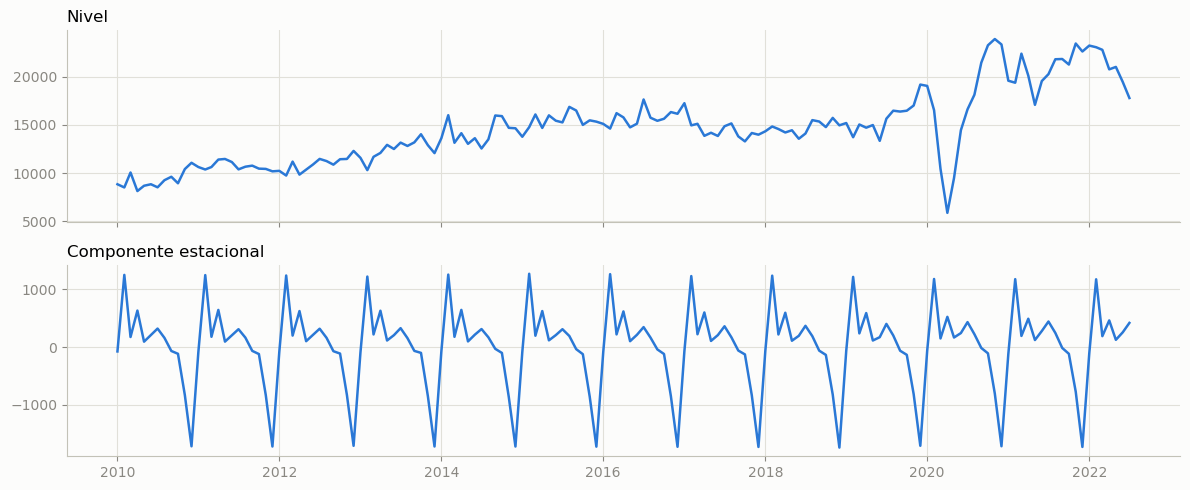

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(ets.states['level'])
axes[0].set_title('Nivel')
axes[1].plot(ets.states['seasonal'])
axes[1].set_title('Componente estacional')
plt.tight_layout()
plt.show()

In [20]:
# Error dentro de train (lo que muestra summary() en R como "Training set error measures")
accuracy(train, ets.fittedvalues, train).to_frame('ETS train').T

,ME,RMSE,MAE,MPE,MAPE,MASE
ETS train,58.12,"1,441.05","1,021.70",-0.10,7.34,0.53


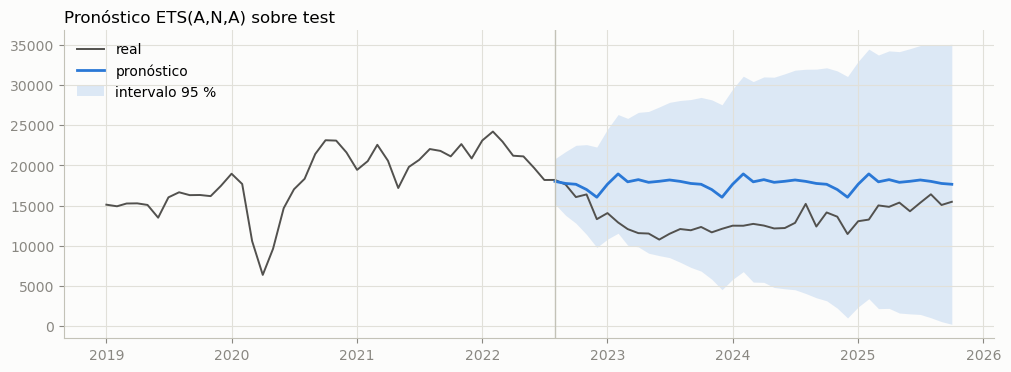

In [21]:
p = ets.get_prediction(start=test.index[0], end=test.index[-1]).summary_frame(alpha=0.05)
pronosticos['ETS'] = p.rename(columns={'mean': 'pronostico', 'pi_lower': 'inf95', 'pi_upper': 'sup95'})

fig, ax = plt.subplots()
graficar_pronostico(ax, 'ETS', pronosticos['ETS'], f'Pronóstico {nombre_ets} sobre test')
ax.legend()
plt.show()

### 3.3 ARIMA

Un **ARIMA(p, d, q)(P, D, Q)[12]** tiene una parte regular y una parte estacional:

- **AR(p)**: la serie depende de sus propios valores pasados. El orden se identifica donde se corta la **PACF**.
- **I(d)**: número de diferencias para quitar la tendencia.
- **MA(q)**: la serie depende de los errores pasados. El orden se identifica donde se corta la **ACF**.
- **(P, D, Q)[12]**: lo mismo, pero con rezagos de 12 meses (la parte estacional).

`auto_arima()` es una versión simplificada de `auto.arima()` de R:

1. Elige **D** con la fuerza de la estacionalidad (D = 1 si supera 0.64) y **d** con la prueba KPSS, igual que `ndiffs()` en R.
2. Prueba todas las combinaciones de p, q ≤ 2 y P, Q ≤ 1, con y sin *drift* (pendiente), y se queda con la de menor AIC.
3. Igual que R, descarta los modelos con raíces casi unitarias (casi no estacionarios o no invertibles).

Los errores estándar se calculan con `cov_type='oim'` (matriz de información observada, lo más parecido a lo que usa R). Los que `statsmodels` calcula por defecto (OPG) son poco confiables para dummies de un solo mes, como las de los atípicos.

> La búsqueda ajusta 72 modelos, así que tarda alrededor de un minuto.

In [22]:
def ndiffs(y, alpha=0.05, max_d=2):
    # Diferencia hasta que la prueba KPSS no rechace la estacionariedad
    d = 0
    while d < max_d and kpss(y.dropna(), regression='c', nlags='auto')[1] < alpha:
        y = y.diff()
        d += 1
    return d

def auto_arima(y, exog=None, m=12, max_p=2, max_q=2, max_P=1, max_Q=1):
    D = int(fuerza_estacional(y, m) > 0.64)
    d = ndiffs(y.diff(m) if D else y)
    tendencias = {0: ['c', 'n'], 1: ['t', 'n']}.get(d + D, ['n'])   # con 2 diferencias no hay constante ni drift
    resultados, mejor, mejor_nombre = [], None, None
    for p, q, P, Q, tendencia in itertools.product(range(max_p + 1), range(max_q + 1),
                                                   range(max_P + 1), range(max_Q + 1), tendencias):
        try:
            modelo = ARIMA(y, exog=exog, order=(p, d, q), seasonal_order=(P, D, Q, m),
                           trend=tendencia).fit(cov_type='oim')
        except Exception:
            continue
        raices = np.abs(np.r_[modelo.arroots, modelo.maroots])
        if len(raices) and raices.min() < 1.01:
            continue
        extra = {'c': ' con constante', 't': ' con drift', 'n': ''}[tendencia]
        nombre = f'ARIMA({p},{d},{q})({P},{D},{Q})[{m}]{extra}'
        resultados.append({'modelo': nombre, 'AIC': modelo.aic})
        if mejor is None or modelo.aic < mejor.aic:
            mejor, mejor_nombre = modelo, nombre
    return mejor, mejor_nombre, pd.DataFrame(resultados).sort_values('AIC', ignore_index=True)

arima, nombre_arima, tabla_arima = auto_arima(train)
print('Modelo elegido:', nombre_arima)
tabla_arima.head()

Modelo elegido: ARIMA(1,1,2)(0,0,0)[12] con drift


,modelo,AIC
0,"ARIMA(1,1,2)(0,0,0)[12] con drift","2,609.45"
1,"ARIMA(2,1,1)(0,0,0)[12] con drift","2,609.46"
2,"ARIMA(2,1,1)(1,0,0)[12] con drift","2,611.08"
3,"ARIMA(1,1,2)(1,0,0)[12] con drift","2,611.10"
4,"ARIMA(2,1,1)(0,0,1)[12] con drift","2,611.19"


In [23]:
print(arima.summary())

                               SARIMAX Results                                
Dep. Variable:                 ventas   No. Observations:                  151
Model:                 ARIMA(1, 1, 2)   Log Likelihood               -1299.723
Date:                Wed, 21 Oct 2026   AIC                           2609.446
Time:                        20:34:49   BIC                           2624.499
Sample:                    01-01-2010   HQIC                          2615.562
                         - 07-01-2022                                         
Covariance Type:                  oim                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1            86.4773     29.042      2.978      0.003      29.557     143.398
ar.L1          0.5380      0.121      4.450      0.000       0.301       0.775
ma.L1         -0.5473      0.123     -4.467      0.0

- **d = 1**: la serie necesita una diferencia regular. **D = 0**: no hace falta la diferencia estacional, como sugerían la ACF y la fuerza estacional.
- El **drift** es la pendiente promedio: cuántas unidades por mes crecen las ventas en train.

**Comparación con R:** `auto.arima(train, stepwise = FALSE, approximation = FALSE)` da el mismo modelo, ARIMA(1,1,2) with drift. El `auto.arima(train)` por defecto (búsqueda *stepwise*) se queda en ARIMA(0,1,0), que tiene un AIC más alto: la búsqueda por pasos es más rápida pero no garantiza encontrar el mejor.

In [24]:
accuracy(train.iloc[1:], arima.fittedvalues.iloc[1:], train).to_frame('ARIMA train').T   # el primer ajuste se descarta por la diferencia

,ME,RMSE,MAE,MPE,MAPE,MASE
ARIMA train,29.35,"1,400.63","1,042.49",-0.50,7.51,0.54


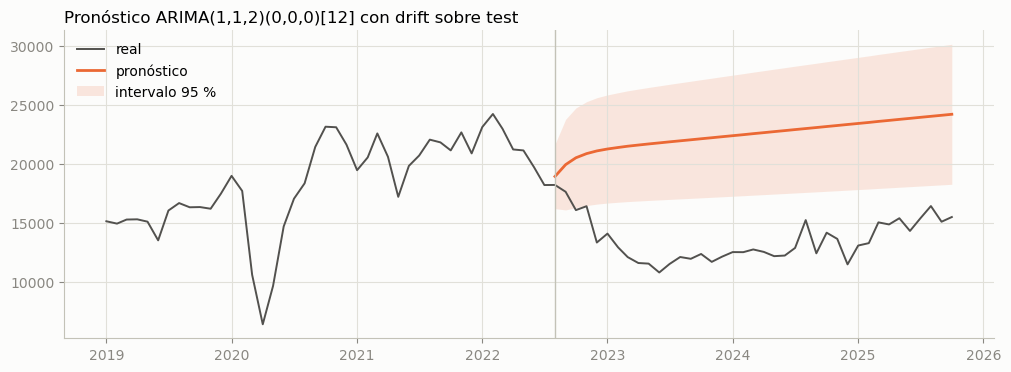

In [25]:
p = arima.get_forecast(len(test)).summary_frame(alpha=0.05)
pronosticos['ARIMA'] = p.rename(columns={'mean': 'pronostico', 'mean_ci_lower': 'inf95', 'mean_ci_upper': 'sup95'})

fig, ax = plt.subplots()
graficar_pronostico(ax, 'ARIMA', pronosticos['ARIMA'], f'Pronóstico {nombre_arima} sobre test')
ax.legend()
plt.show()

El drift empuja el pronóstico hacia arriba justo cuando las ventas reales se desploman. El modelo aprendió de train que "las ventas crecen", y nada en esos datos le anuncia la caída.

## 4. Atípicos

Cuando un atípico no es un error de medición no se puede borrar: se modela con una **dummy por cada atípico** que luego entra al ARIMAX (Clase 16). Según su forma hay tres tipos:

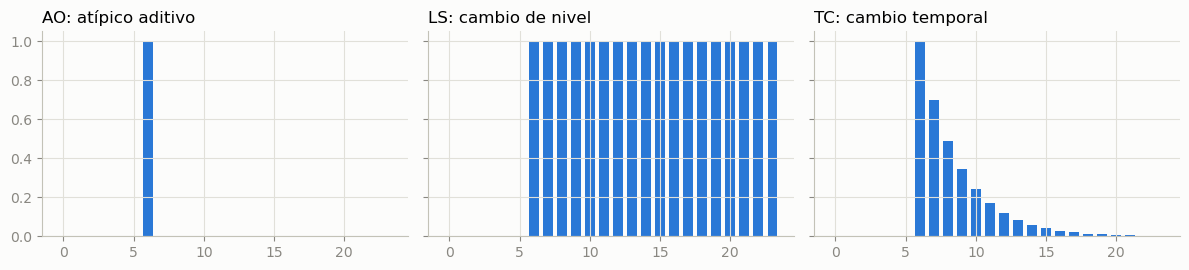

In [26]:
def patron_atipico(tipo, t0, n, delta=0.7):
    x = np.zeros(n)
    if tipo == 'AO':
        x[t0] = 1                              # atípico aditivo: un solo mes
    elif tipo == 'LS':
        x[t0:] = 1                             # cambio de nivel: 1, 1, 1, ... de ahí en adelante
    elif tipo == 'TC':
        x[t0:] = delta ** np.arange(n - t0)    # cambio temporal: 1, 0.7, 0.49, ... se va desvaneciendo
    return x

fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
titulos = {'AO': 'AO: atípico aditivo', 'LS': 'LS: cambio de nivel', 'TC': 'TC: cambio temporal'}
for ax, (tipo, titulo) in zip(axes, titulos.items()):
    ax.bar(range(24), patron_atipico(tipo, 6, 24), width=0.7)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

### Detección automática (equivalente a `tso()`)

En R usamos `tso()` del paquete `tsoutliers`, que no tiene equivalente en `statsmodels`. `detectar_atipicos()` es una versión simplificada del mismo método (Chen y Liu, 1993):

1. Ajusta el ARIMA y calcula sus residuos.
2. Para cada mes y cada tipo (AO, LS, TC), estima cuánto de los residuos explicaría un atípico ahí y calcula su estadístico *t*.
3. Si el mayor |t| supera el valor crítico, agrega ese atípico como regresor y vuelve al paso 1. El valor crítico por defecto es el mismo de `tso()`: 3.25 para 151 datos.
4. Al final ajusta todos los atípicos juntos y elimina los que dejen de ser significativos.

In [27]:
def detectar_atipicos(y, modelo, cval=None, delta=0.7, max_atipicos=10):
    # Mismo orden (p,d,q)(P,D,Q) y tendencia del modelo dado
    spec = dict(order=modelo.model.order, seasonal_order=modelo.model.seasonal_order, trend=modelo.model.trend)
    n = len(y)
    if cval is None:
        cval = float(np.clip(3 + 0.0025 * (n - 50), 3, 4))   # valor crítico por defecto de tso()
    (_, d, _), (_, D, _, m) = spec['order'], spec['seasonal_order']
    diferencia = np.array([1.0])                             # polinomio (1 - B)^d (1 - B^m)^D
    for _ in range(d):
        diferencia = np.convolve(diferencia, [1, -1])
    for _ in range(D):
        diferencia = np.convolve(diferencia, np.r_[1, np.zeros(m - 1), -1])
    inicio = d + D * m + 1                                   # los primeros residuos no son confiables

    X = pd.DataFrame(index=y.index)
    while X.shape[1] < max_atipicos:
        ajuste = ARIMA(y, exog=X if X.shape[1] else None, **spec).fit(cov_type='oim')
        e = ajuste.resid.values.copy()
        e[:inicio] = 0
        sigma = 1.483 * np.median(np.abs(e - np.median(e)))  # desviación estándar robusta (MAD)
        # Filtro del modelo: convierte un patrón de atípico en su huella sobre los residuos
        ar = np.convolve(np.convolve(ajuste.polynomial_ar, ajuste.polynomial_seasonal_ar), diferencia)
        ma = np.convolve(ajuste.polynomial_ma, ajuste.polynomial_seasonal_ma)
        mejor = None
        for t0 in range(inicio, n):
            for tipo in ['AO', 'LS', 'TC']:
                if f'{tipo}_{y.index[t0]:%Y-%m}' in X:
                    continue
                huella = lfilter(ar, ma, patron_atipico(tipo, t0, n, delta))
                tstat = (huella @ e) / (sigma * np.sqrt(huella @ huella))
                if mejor is None or abs(tstat) > abs(mejor[0]):
                    mejor = (tstat, tipo, t0)
        tstat, tipo, t0 = mejor
        if abs(tstat) < cval:
            print(f'  siguiente candidato: {tipo} {y.index[t0]:%Y-%m} (t = {tstat:.2f}), no supera {cval:.2f}: paramos')
            break
        print(f'  agregado {tipo} {y.index[t0]:%Y-%m}  (t = {tstat:.2f})')
        X[f'{tipo}_{y.index[t0]:%Y-%m}'] = patron_atipico(tipo, t0, n, delta)

    # Ajuste conjunto: se eliminan uno a uno los atípicos que dejen de ser significativos
    while True:
        ajuste = ARIMA(y, exog=X if X.shape[1] else None, **spec).fit(cov_type='oim')
        if X.shape[1] == 0:
            break
        t = ajuste.tvalues[X.columns].abs()
        if t.min() >= cval:
            break
        print(f'  eliminado {t.idxmin()}  (t = {t.min():.2f} en el ajuste conjunto)')
        X = X.drop(columns=t.idxmin())

    tabla = pd.DataFrame({'tipo': [c.split('_')[0] for c in X], 'fecha': [c.split('_')[1] for c in X],
                          'coef': ajuste.params[X.columns].values, 'tstat': ajuste.tvalues[X.columns].values})
    return tabla.sort_values('fecha', ignore_index=True), X

atipicos, X_atipicos = detectar_atipicos(train, arima)
atipicos

  agregado TC 2020-03  (t = -4.53)
  agregado TC 2020-04  (t = -6.00)


  agregado AO 2014-02  (t = 4.78)


  agregado AO 2021-05  (t = -3.63)


  siguiente candidato: LS 2020-06 (t = 3.11), no supera 3.25: paramos


,tipo,fecha,coef,tstat
0,AO,2014-02,"3,817.98",4.59
1,TC,2020-03,"-7,677.83",-7.42
2,TC,2020-04,"-7,069.76",-6.84
3,AO,2021-05,"-3,014.81",-3.67


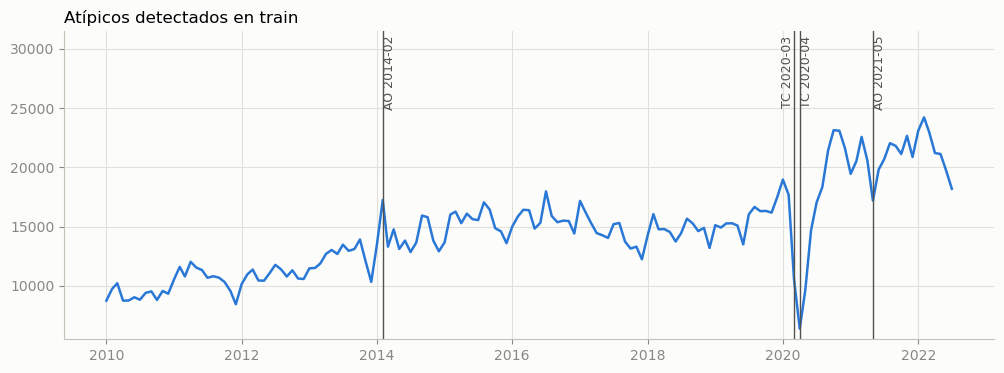

In [28]:
fig, ax = plt.subplots()
ax.plot(train, color=COLORES[0])
fechas = pd.to_datetime(atipicos['fecha'])
for i, fila in atipicos.iterrows():
    # si el siguiente atípico está a menos de 3 meses, esta etiqueta va a la izquierda de la línea
    pegado_al_siguiente = i + 1 < len(fechas) and (fechas[i + 1] - fechas[i]).days < 90
    ax.axvline(fechas[i], color=GRIS, lw=1)
    ax.text(fechas[i], train.max() * 1.3, f" {fila['tipo']} {fila['fecha']} ", rotation=90, va='top',
            ha='right' if pegado_al_siguiente else 'left', color=GRIS, fontsize=9)
ax.set_ylim(top=train.max() * 1.3)
ax.set_title('Atípicos detectados en train')
plt.show()

**Comparación con R.** `tso(train)` encuentra AO 2014-02, TC 2020-03, LS 2020-06 y AO 2021-05. Nuestra versión simplificada encuentra casi los mismos eventos, aunque no siempre con el mismo tipo ni el mismo mes. Lo importante es que coinciden con las dummies que ya trae el Excel:

| Dummy del Excel | Meses | `tso()` en R | `detectar_atipicos()` | Evento |
|---|---|---|---|---|
| `pandemia` | 2020-03 | TC 2020-03 | TC 2020-03 y TC 2020-04 | Desplome por el confinamiento |
| `reactivacion` | desde 2020-06 | LS 2020-06 | LS 2020-06 queda justo por debajo del umbral | Nuevo nivel de ventas tras la reapertura |
| `paro` | 2021-05 | AO 2021-05 | AO 2021-05 | Paro nacional |
| *(no está)* | 2014-02 | AO 2014-02 | AO 2014-02 | Pico aislado: le creamos una dummy, `ao_2014_02` |
| `crisis_mcy` | desde 2023-03 | — | — | Está toda en test |

Para el ARIMAX usamos las dummies del Excel, que tienen nombre y significado, más la de feb-2014.

## 5. ARIMAX: ARIMA con predictores

A un ARIMA le podemos meter predictores X (regresión con errores ARIMA, `auto.arima(xreg = )` en R). Tres cuidados de la clase:

1. **El predictor debe tener rezago** (ojalá alto): para pronosticar el mes siguiente necesito conocer X, y si X está rezagada ya la conozco. Usamos la tasa de interés VIS **del mes anterior**.
2. Los **AIC de ARIMA y ARIMAX se pueden comparar**, siempre que se ajusten sobre la misma muestra.
3. `crisis_mcy` vale 0 en todo train (empieza en marzo 2023), así que el modelo **no puede aprender su efecto** y la dejamos por fuera. Una columna constante no aporta información, y en R `auto.arima` la descartaría. En el modelo final, con todos los datos, revisamos si aporta.

¿Qué X usar? Las tasas de interés son las variables más correlacionadas con las ventas en train:

In [29]:
predictores = ['desempleo', 'ipc', 'tasa_no_vis', 'tasa_vis', 'iccv', 'icc']
datos.loc[:'2022-07', ['ventas'] + predictores].corr()['ventas'].drop('ventas').sort_values().to_frame('correlación con ventas')

,correlación con ventas
tasa_no_vis,-0.74
tasa_vis,-0.70
icc,-0.60
desempleo,0.17
ipc,0.33
iccv,0.34


Las dos tasas se mueven casi igual (correlación ≈ 0.95), así que meter ambas sería redundante. Usamos la **tasa VIS**, porque la mayoría de las viviendas nuevas que se venden en Colombia son VIS. Como ejercicio, pruebe con `tasa_no_vis` y compare el AIC.

In [30]:
datos['tasa_vis_L1'] = datos['tasa_vis'].shift(1)                  # tasa VIS del mes anterior
datos['ao_2014_02'] = (datos.index == '2014-02-01').astype(int)     # dummy para el atípico de feb-2014

regresores = ['tasa_vis_L1', 'pandemia', 'paro', 'reactivacion', 'ao_2014_02']
muestra = slice('2010-02', '2022-07')                               # se pierde enero 2010 por el rezago
X_train = datos.loc[muestra, regresores]
X_test = datos.loc['2022-08':, regresores]

arimax, nombre_arimax, tabla_arimax = auto_arima(train[muestra], exog=X_train)
print('Modelo elegido: regresión con errores', nombre_arimax)
print(arimax.summary())

Modelo elegido: regresión con errores ARIMA(1,1,2)(1,0,1)[12]
                                     SARIMAX Results                                      
Dep. Variable:                             ventas   No. Observations:                  150
Model:             ARIMA(1, 1, 2)x(1, 0, [1], 12)   Log Likelihood               -1273.276
Date:                            Wed, 21 Oct 2026   AIC                           2568.551
Time:                                    20:35:13   BIC                           2601.594
Sample:                                02-01-2010   HQIC                          2581.976
                                     - 07-01-2022                                         
Covariance Type:                              oim                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
tasa_vis_L1  -1789.7167    618.426     -2.894   

In [31]:
# AIC sobre la misma muestra (desde feb-2010): ARIMA univariado vs. ARIMAX
arima_misma_muestra = ARIMA(train[muestra], order=arima.model.order,
                            seasonal_order=arima.model.seasonal_order, trend=arima.model.trend).fit()
pd.Series({nombre_arima: arima_misma_muestra.aic, f'ARIMAX: {nombre_arimax}': arimax.aic}, name='AIC').to_frame()

,AIC
"ARIMA(1,1,2)(0,0,0)[12] con drift","2,591.18"
"ARIMAX: ARIMA(1,1,2)(1,0,1)[12]","2,568.55"


- El ARIMAX tiene un AIC claramente menor: las dummies y la tasa de interés explican parte de lo que el ARIMA univariado dejaba en los errores.
- El coeficiente de `tasa_vis_L1` es negativo: cada punto porcentual adicional en la tasa VIS del mes anterior se asocia con unas 1.800 unidades vendidas menos al mes.
- Las dummies tienen el signo esperado: pandemia y paro negativos, reactivación y feb-2014 positivos. La de pandemia no es significativa por sí sola (en R tampoco), porque el ARIMA ya sigue en parte la caída de 2020.

**Pronóstico ex post.** Para evaluar en test usamos los valores reales de X en esos meses. Como X está rezagada un mes, en la vida real solo la conoceríamos para el primer mes; para más meses habría que suponer escenarios de tasas (lo hacemos en la sección 9).

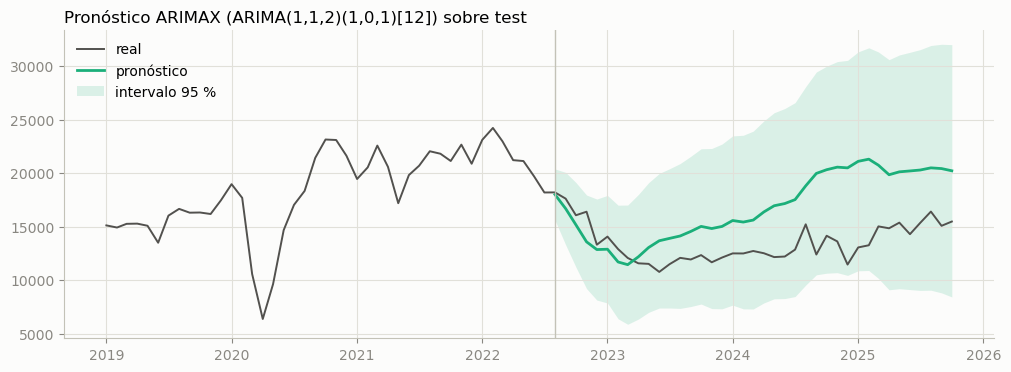

In [32]:
p = arimax.get_forecast(len(test), exog=X_test).summary_frame(alpha=0.05)
pronosticos['ARIMAX'] = p.rename(columns={'mean': 'pronostico', 'mean_ci_lower': 'inf95', 'mean_ci_upper': 'sup95'})

fig, ax = plt.subplots()
graficar_pronostico(ax, 'ARIMAX', pronosticos['ARIMAX'], f'Pronóstico ARIMAX ({nombre_arimax}) sobre test')
ax.legend()
plt.show()

## 6. Supuestos: los residuos deben ser ruido blanco

Los errores no deben tener ningún patrón visible. Dos pruebas:

- **Dickey-Fuller aumentada** (`adf.test`): $H_0$ = los residuos tienen raíz unitaria. Queremos **p < 0.05** (residuos estacionarios).
- **Ljung-Box** (`Box.test(..., lag = 20)`): $H_0$ = no hay autocorrelación en los primeros 20 rezagos. Queremos **p > 0.05**.

Si fallan las pruebas, sospechamos que el modelo no es robusto.

In [33]:
def pruebas_residuos(modelo):
    burn = getattr(modelo, 'loglikelihood_burn', 0)   # en los ARIMA con d = 1 el primer residuo no sirve
    r = modelo.resid.iloc[burn:]
    adf_p = adfuller(r)[1]
    lb_p = acorr_ljungbox(r, lags=[20]).lb_pvalue.iloc[0]
    return pd.Series({'ADF p-valor': adf_p, 'ADF ok (p < 0.05)': adf_p < 0.05,
                      'Ljung-Box p-valor': lb_p, 'Ljung-Box ok (p > 0.05)': lb_p > 0.05})

modelos = {'ETS': ets, 'ARIMA': arima, 'ARIMAX': arimax}
pd.DataFrame({nombre: pruebas_residuos(m) for nombre, m in modelos.items()}).T

,ADF p-valor,ADF ok (p < 0.05),Ljung-Box p-valor,Ljung-Box ok (p > 0.05)
ETS,0.00,True,0.02,False
ARIMA,0.00,True,0.98,True
ARIMAX,0.00,True,0.66,True


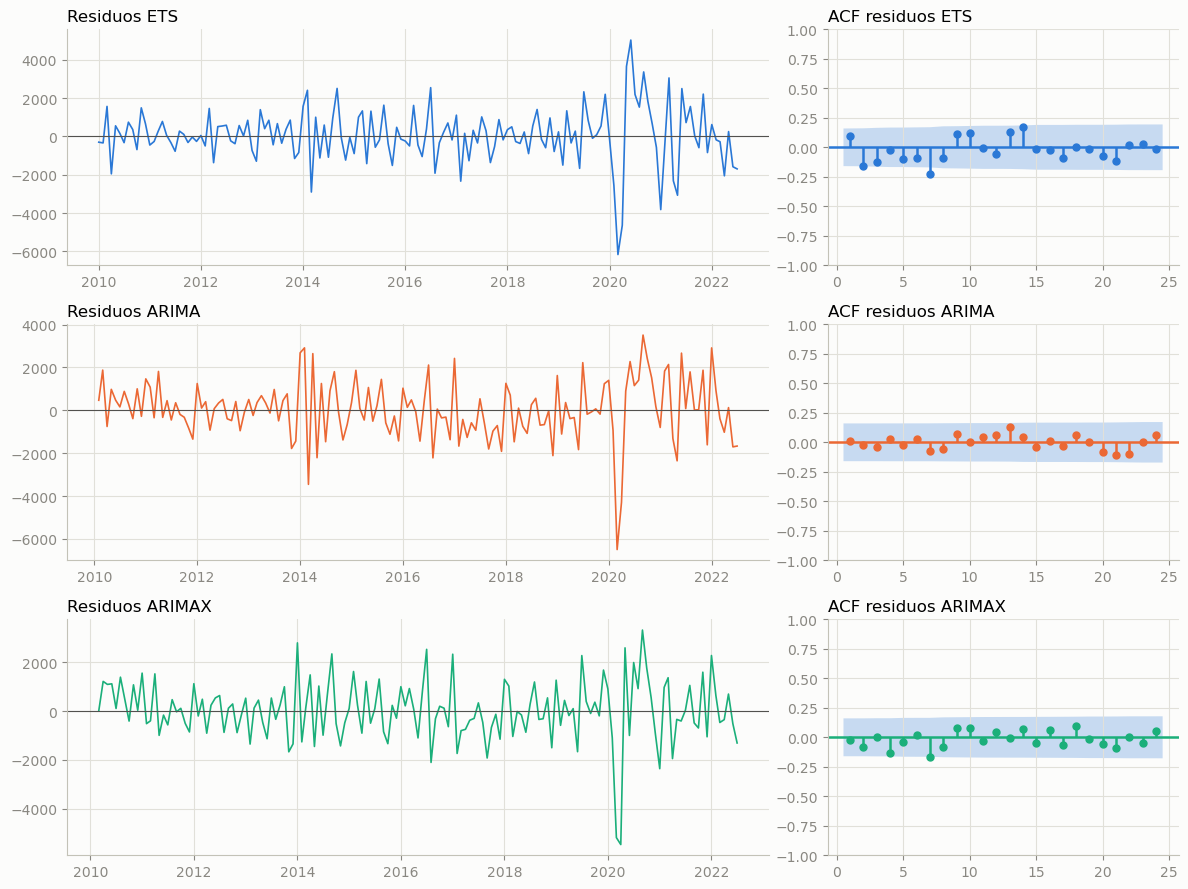

In [34]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), gridspec_kw={'width_ratios': [2, 1]})
for fila, (nombre, m) in zip(axes, modelos.items()):
    r = m.resid.iloc[getattr(m, 'loglikelihood_burn', 0):]
    fila[0].plot(r, color=COLOR_MODELO[nombre], lw=1.2)
    fila[0].axhline(0, color=GRIS, lw=0.8)
    fila[0].set_title(f'Residuos {nombre}')
    plot_acf(r, lags=24, zero=False, ax=fila[1], title=f'ACF residuos {nombre}', color=COLOR_MODELO[nombre],
             vlines_kwargs={'colors': COLOR_MODELO[nombre]})
plt.tight_layout()
plt.show()

- Los tres modelos pasan Dickey-Fuller: los residuos son estacionarios.
- El **ETS no pasa Ljung-Box**: le queda autocorrelación en los residuos (también pasa en R, donde p ≈ 0.02). ARIMA y ARIMAX sí la pasan.
- Los residuos más grandes están en la pandemia. La dummy `pandemia` solo marca marzo 2020, así que el desplome de abril sigue apareciendo como un residuo grande en el ARIMAX. Los dos TC que detectamos (marzo y abril) lo absorberían mejor: queda como ejercicio.

## 7. Evaluación en test

In [35]:
orden = ['Ingenuo', 'Ingenuo estacional', 'ETS', 'ARIMA', 'ARIMAX']
tabla_test = pd.DataFrame({nombre: accuracy(test, pronosticos[nombre]['pronostico'], train) for nombre in orden}).T
tabla_test

,ME,RMSE,MAE,MPE,MAPE,MASE
Ingenuo,"-4,632.95","4,978.76","4,633.31",-36.44,36.44,2.42
Ingenuo estacional,"-8,031.36","8,340.99","8,031.36",-61.77,61.77,4.19
ETS,"-4,227.57","4,636.59","4,236.82",-33.36,33.42,2.21
ARIMA,"-8,878.22","9,166.39","8,878.22",-68.31,68.31,4.63
ARIMAX,"-3,319.78","4,386.56","3,745.12",-25.29,28.13,1.95


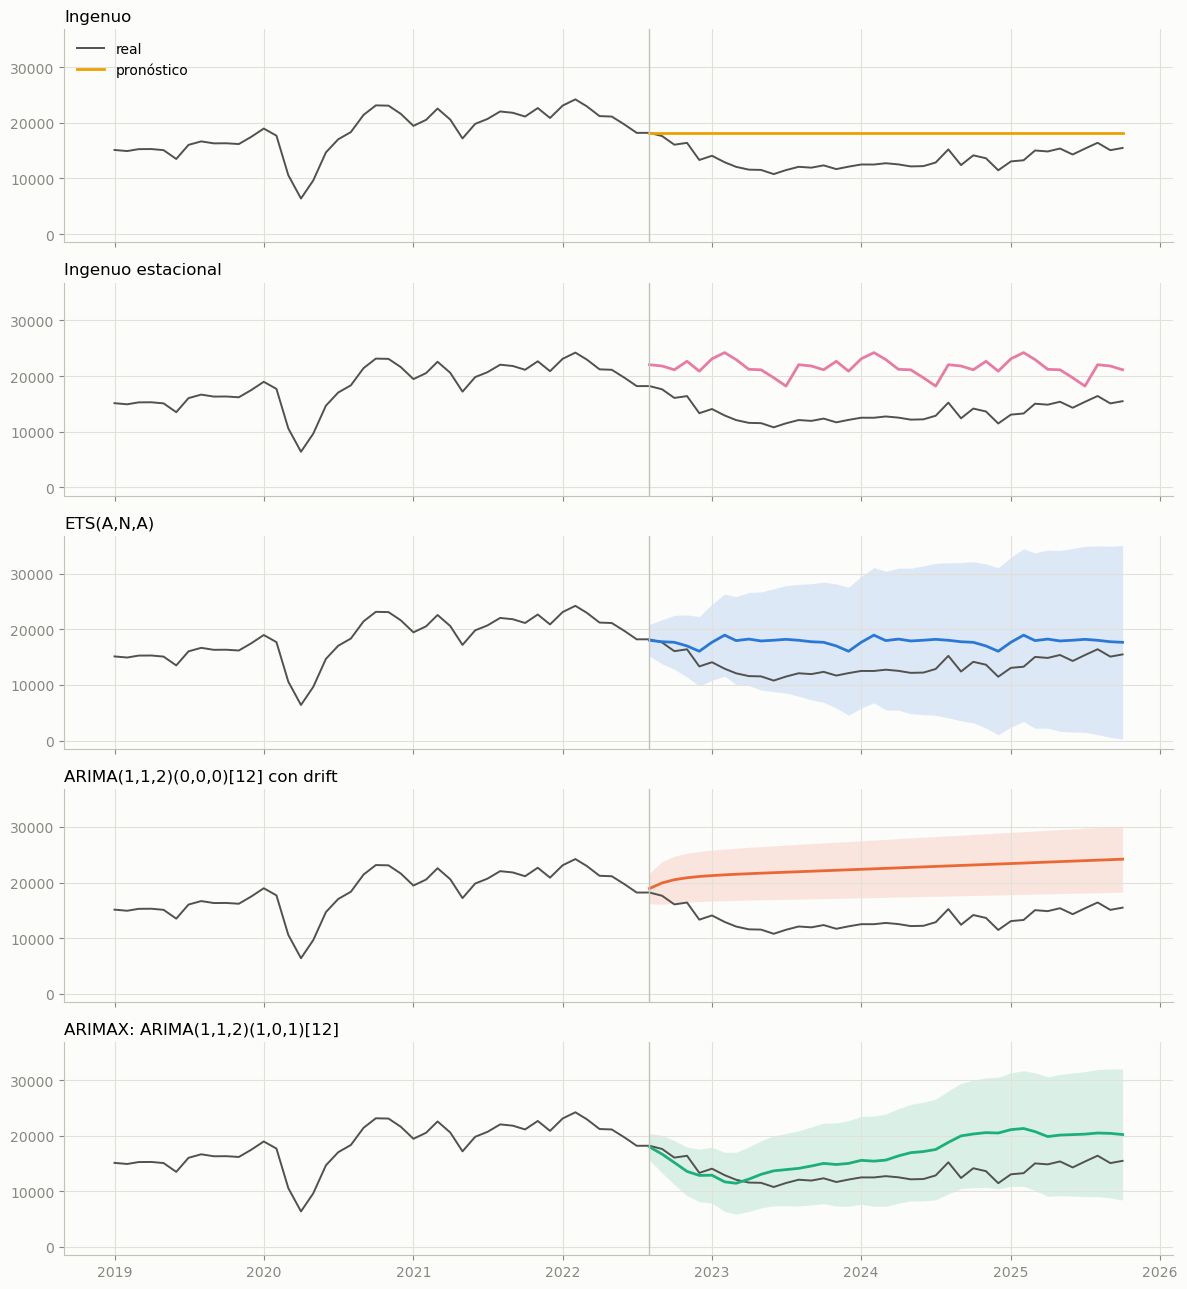

In [36]:
fig, axes = plt.subplots(len(orden), 1, figsize=(12, 13), sharex=True, sharey=True)
titulos = {'ETS': nombre_ets, 'ARIMA': nombre_arima, 'ARIMAX': f'ARIMAX: {nombre_arimax}'}
for ax, nombre in zip(axes, orden):
    graficar_pronostico(ax, nombre, pronosticos[nombre], titulos.get(nombre, nombre))
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

- **Todos los modelos sobreestiman** (ME y MPE negativos) y tienen MASE > 1: ninguno anticipa el desplome de 2023, porque es un cambio estructural que no está en train.
- El **ARIMAX es el menos malo**: la subida de las tasas (que entra como X) explica parte de la caída. Aun así se queda corto, porque el efecto de la crisis de *Mi Casa Ya* no lo puede aprender.
- El ARIMA univariado es el peor: su drift sigue apuntando hacia arriba.

Esto ilustra lo que advierte la Clase 15: **elegir como test un solo bloque al final de la serie tiene un riesgo grave**. El resultado depende de lo que pase justo en ese bloque. Para medir mejor qué tan bueno es cada modelo usamos la validación escalonada en origen.

## 8. Validación escalonada en origen (`tsCV`)

Es el equivalente de la validación cruzada en series de tiempo: para cada mes *t* (el "origen") se entrena con los datos hasta *t* y se pronostican los meses *t+1, …, t+12*. Así cada modelo se evalúa sobre muchos orígenes y no solo sobre el último bloque. Es costosa computacionalmente: hay que reajustar el modelo en cada origen.

- Mantenemos la especificación de cada modelo (el orden del ARIMA, el tipo de ETS) y re-estimamos sus parámetros en cada origen.
- Usamos toda la serie, desde feb-2010 para que todos los modelos tengan la misma muestra, con 60 meses iniciales (`initial = 60` en R).
- En el ARIMAX, una dummy cuyo evento todavía no ha ocurrido en el origen *t* vale 0 en todo el pasado y no se puede estimar, así que se deja por fuera. Las X futuras son las reales (pronóstico ex post).

> **Ojo con el script de R:** `far2` y `far3` ajustan sobre `producto1` y `producto1.train` en lugar de sobre `x`, así que no re-entrenan en cada origen. La función de pronóstico siempre debe usar su argumento `x`.

> Esta celda tarda un par de minutos.

In [37]:
def ts_cv(y, pronosticar, h=12, inicial=60, X=None):
    # Fila t = origen; columna h=k = error al pronosticar k meses adelante desde t (igual que tsCV de R)
    errores = pd.DataFrame(np.nan, index=y.index, columns=[f'h={k}' for k in range(1, h + 1)])
    for t in range(inicial, len(y) - 1):
        pasos = min(h, len(y) - 1 - t)
        historia = y.iloc[:t + 1]
        if X is None:
            f = pronosticar(historia, pasos)
        else:
            f = pronosticar(historia, pasos, X.iloc[:t + 1], X.iloc[t + 1:t + 1 + pasos])
        errores.iloc[t, :pasos] = y.iloc[t + 1:t + 1 + pasos].values - np.asarray(f)
    return errores

spec_ets = dict(error=ets.model.error, trend=ets.model.trend, damped_trend=ets.model.damped_trend,
                seasonal=ets.model.seasonal, seasonal_periods=ets.model.seasonal_periods,
                initialization_method='heuristic')
spec_arima = dict(order=arima.model.order, seasonal_order=arima.model.seasonal_order, trend=arima.model.trend)
spec_arimax = dict(order=arimax.model.order, seasonal_order=arimax.model.seasonal_order, trend=arimax.model.trend)

def f_ingenuo(x, h):
    return np.repeat(x.iloc[-1], h)

def f_ingenuo_estacional(x, h):
    return np.resize(x.iloc[-12:].values, h)

def f_ets(x, h):
    return ETSModel(x, **spec_ets).fit(disp=False).forecast(h)

def f_arima(x, h):
    return ARIMA(x, **spec_arima).fit().forecast(h)

def f_arimax(x, h, X_hist, X_futuro):
    columnas = X_hist.columns[X_hist.std() > 0]   # dummies de eventos que todavía no han ocurrido
    return ARIMA(x, exog=X_hist[columnas], **spec_arimax).fit().forecast(h, exog=X_futuro[columnas])

y_cv = ventas['2010-02':]
X_cv = datos.loc['2010-02':, regresores]
errores_cv = {
    'Ingenuo': ts_cv(y_cv, f_ingenuo),
    'Ingenuo estacional': ts_cv(y_cv, f_ingenuo_estacional),
    'ETS': ts_cv(y_cv, f_ets),
    'ARIMA': ts_cv(y_cv, f_arima),
    'ARIMAX': ts_cv(y_cv, f_arimax, X=X_cv),
}
rmse_cv = pd.DataFrame({nombre: np.sqrt((e ** 2).mean()) for nombre, e in errores_cv.items()})
rmse_cv.loc['promedio'] = rmse_cv.mean()
rmse_cv.round(0)

,Ingenuo,Ingenuo estacional,ETS,ARIMA,ARIMAX
h=1,"1,554.00","3,876.00","1,695.00","1,605.00","1,684.00"
h=2,"2,311.00","3,883.00","2,328.00","2,359.00","2,167.00"
h=3,"2,719.00","3,898.00","2,710.00","2,748.00","2,387.00"
h=4,"2,978.00","3,904.00","3,003.00","3,036.00","2,544.00"
h=5,"3,161.00","3,916.00","3,284.00","3,256.00","2,682.00"
h=6,"3,343.00","3,925.00","3,503.00","3,471.00","2,749.00"
h=7,"3,540.00","3,929.00","3,596.00","3,665.00","2,775.00"
h=8,"3,658.00","3,945.00","3,595.00","3,827.00","2,708.00"
h=9,"3,689.00","3,960.00","3,581.00","3,978.00","2,644.00"
h=10,"3,791.00","3,976.00","3,695.00","4,150.00","2,732.00"


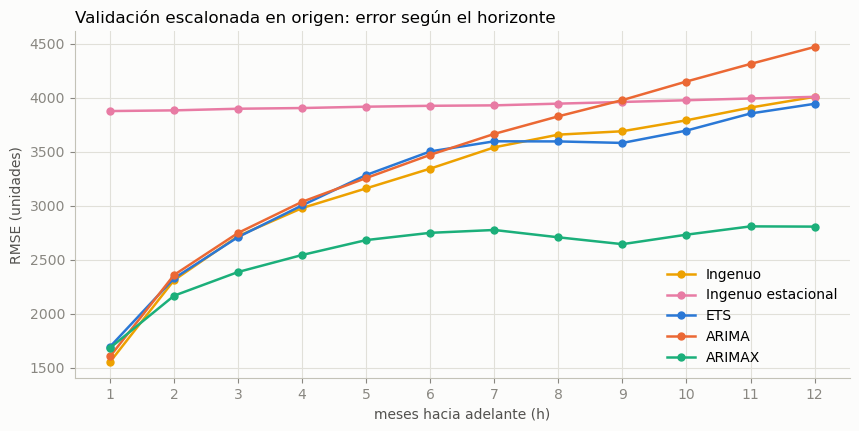

In [38]:
fig, ax = plt.subplots(figsize=(10, 4.5))
horizontes = range(1, 13)
for nombre in orden:
    valores = rmse_cv.loc[[f'h={k}' for k in horizontes], nombre].values
    ax.plot(horizontes, valores, marker='o', markersize=5, color=COLOR_MODELO[nombre], label=nombre)
ax.set_xticks(list(horizontes))
ax.set_xlabel('meses hacia adelante (h)')
ax.set_ylabel('RMSE (unidades)')
ax.set_title('Validación escalonada en origen: error según el horizonte')
ax.legend(loc='lower right')
plt.show()

- Como es de esperar, el error crece con el horizonte: pronosticar 12 meses adelante es más difícil que pronosticar uno.
- A un mes, el ingenuo es difícil de superar. Desde h = 2, el **ARIMAX tiene el menor RMSE** en todos los horizontes. ETS e ingenuo quedan muy parejos, y el ARIMA empeora en horizontes largos por el drift.
- El ingenuo estacional es el peor a corto plazo: un año atrás es demasiado lejos cuando la serie cambia tanto de nivel.

Este veredicto es más confiable que el de un único bloque de test, porque promedia muchos orígenes. Una advertencia: aquí el ARIMAX usa las tasas reales de los meses futuros, así que su ventaja es optimista. En la práctica dependería de qué tan bien anticipemos la tasa.

## 9. Modelo final y pronóstico

Re-estimamos el ARIMAX con **todos** los datos (feb-2010 a oct-2025), manteniendo la especificación elegida. Ahora `crisis_mcy` ya tiene meses en 1 y se puede estimar. ¿Mejora el modelo? Lo decidimos con el AIC:

In [39]:
y_total = ventas['2010-02':]
X_total = datos.loc['2010-02':, regresores + ['crisis_mcy']]
sin_crisis = ARIMA(y_total, exog=X_total[regresores], **spec_arimax).fit(cov_type='oim')
con_crisis = ARIMA(y_total, exog=X_total, **spec_arimax).fit(cov_type='oim')
pd.DataFrame({'AIC': [sin_crisis.aic, con_crisis.aic],
              't de crisis_mcy': [np.nan, con_crisis.tvalues['crisis_mcy']]},
             index=['sin crisis_mcy', 'con crisis_mcy'])

,AIC,t de crisis_mcy
sin crisis_mcy,"3,222.54",NaN
con crisis_mcy,"3,223.39",-0.72


`crisis_mcy` **no mejora el AIC y no es significativa**. Con d = 1, el modelo trabaja en diferencias, y la diferencia de una dummy escalón es un pulso en el mes en que empieza (marzo 2023). Entonces la dummy solo "ve" el salto de ese mes. Pero la caída fue gradual: venía desde finales de 2022 y la explica en buena parte la subida de las tasas, que ya está en el modelo. Nos quedamos con el modelo sin ella.

Para pronosticar los próximos 12 meses necesitamos un escenario para las X:

- La tasa VIS se mantiene en su último valor observado.
- `reactivacion` sigue en 1; `pandemia`, `paro` y `ao_2014_02` en 0.

In [40]:
modelo_final = sin_crisis
print(modelo_final.summary().tables[1])

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
tasa_vis_L1   -905.4760    284.917     -3.178      0.001   -1463.903    -347.049
pandemia     -1350.8390    857.275     -1.576      0.115   -3031.067     329.389
paro         -2954.2401    862.863     -3.424      0.001   -4645.421   -1263.059
reactivacion  5032.3843   1219.135      4.128      0.000    2642.924    7421.845
ao_2014_02    3815.2288    865.543      4.408      0.000    2118.796    5511.662
ar.L1            0.5495      0.181      3.041      0.002       0.195       0.904
ma.L1           -0.6049      0.184     -3.288      0.001      -0.965      -0.244
ma.L2           -0.1436      0.077     -1.867      0.062      -0.294       0.007
ar.S.L12         0.8631      0.109      7.921      0.000       0.650       1.077
ma.S.L12        -0.7590      0.143     -5.315      0.000      -1.039      -0.479
sigma2        1.407e+06   1.

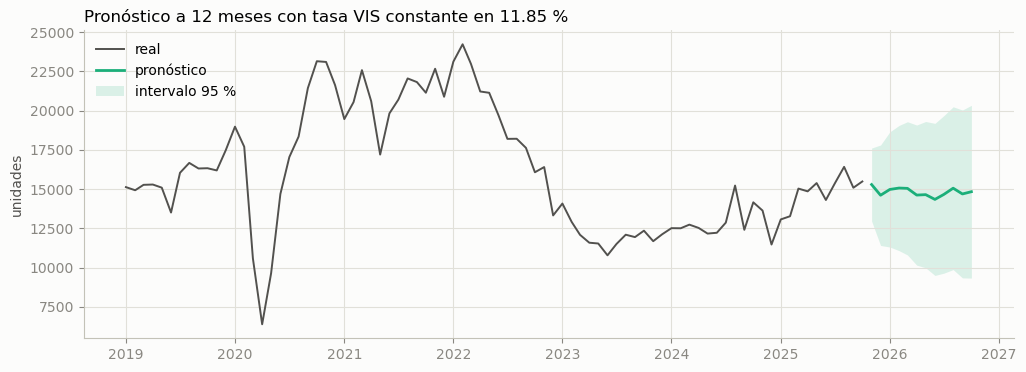

ventas,pronostico,inf95,sup95
2025-11-01,"15,288.00","12,963.00","17,612.00"
2025-12-01,"14,607.00","11,410.00","17,805.00"
2026-01-01,"14,976.00","11,311.00","18,641.00"
2026-02-01,"15,065.00","11,079.00","19,052.00"
2026-03-01,"15,045.00","10,804.00","19,286.00"
2026-04-01,"14,617.00","10,157.00","19,077.00"
2026-05-01,"14,645.00","9,987.00","19,302.00"
2026-06-01,"14,342.00","9,500.00","19,183.00"
2026-07-01,"14,661.00","9,645.00","19,677.00"
2026-08-01,"15,056.00","9,873.00","20,239.00"


In [41]:
fechas_futuras = pd.date_range(ventas.index[-1] + pd.offsets.MonthBegin(), periods=12, freq='MS')
X_futuro = pd.DataFrame({'tasa_vis_L1': datos['tasa_vis'].iloc[-1], 'pandemia': 0, 'paro': 0,
                         'reactivacion': 1, 'ao_2014_02': 0}, index=fechas_futuras)[regresores]

futuro = modelo_final.get_forecast(12, exog=X_futuro).summary_frame(alpha=0.05)
futuro = futuro.rename(columns={'mean': 'pronostico', 'mean_ci_lower': 'inf95', 'mean_ci_upper': 'sup95'})

fig, ax = plt.subplots()
ax.plot(ventas['2019-01':], color=GRIS, lw=1.4, label='real')
ax.plot(futuro['pronostico'], color=COLOR_MODELO['ARIMAX'], lw=2, label='pronóstico')
ax.fill_between(futuro.index, futuro['inf95'], futuro['sup95'], color=COLOR_MODELO['ARIMAX'], alpha=0.15, lw=0,
                label='intervalo 95 %')
ax.set_title(f"Pronóstico a 12 meses con tasa VIS constante en {datos['tasa_vis'].iloc[-1]:.2f} %")
ax.set_ylabel('unidades')
ax.legend(loc='upper left')
plt.show()

futuro[['pronostico', 'inf95', 'sup95']].round(0)

Con un ARIMAX, cambiar el escenario es tan simple como cambiar `X_futuro`. Por ejemplo, si la tasa VIS bajara un punto, el pronóstico subiría, cada mes, en el valor absoluto del coeficiente de `tasa_vis_L1`.

## Resumen

1. **Partición temporal**, no aleatoria. El test debe cubrir el horizonte de planeación y un ciclo estacional.
2. **Exploración**: tendencia, estacionalidad y rupturas. Diferenciar antes de leer la ACF y la PACF.
3. **Modelos**: los ingenuos son la línea base; ETS se interpreta mejor; ARIMA y ARIMAX permiten agregar predictores y dummies.
4. **Atípicos**: no se borran; se modelan con una dummy por cada uno (AO, LS o TC).
5. **Residuos**: ADF con p < 0.05 y Ljung-Box con p > 0.05.
6. **Evaluación**: un único bloque de test puede engañar. La validación escalonada en origen da un veredicto más confiable.

**Ejercicios sugeridos**

- Cambiar `tasa_vis_L1` por la tasa no VIS rezagada y comparar el AIC.
- Reemplazar la dummy `pandemia` por los regresores TC 2020-03 y TC 2020-04 de `X_atipicos` y revisar los residuos y el AIC.
- Mover la partición para que el test sean los últimos 12 meses. Ahora `crisis_mcy` sí tiene meses en 1 dentro de train y puede entrar al modelo.
- Usar la tasa rezagada 12 meses: así se puede pronosticar un año sin inventar escenarios, porque X ya se conoce. ¿Qué tanto empeora el ajuste?